# 3 · Calibration against national accounts, and wage shocks

MarxKapital calibrates its departments from Portuguese national accounts (INE) or from the European Commission's AMECO database. **Everything in this notebook uses the synthetic defaults and runs offline.** Real data are opt-in, as shown at the end.

Calibration maps national-accounts aggregates to Marxian categories: compensation of employees → variable capital `V`, gross operating surplus → surplus value `S`, the capital stock → constant capital `C`. From these follow `e = S/V`, `k = C/V` and `r = S/(C + V)`.

In [1]:
include(joinpath("..", "..", "src", "MarxKapital.jl"))
using Plots, Random, DataFrames
gr(fmt = :png, size = (760, 420), margin = 3Plots.mm)

MarxKapital carregado. Escreva  ajuda_modelo()  para começar.


Plots.GRBackend()

## 1. Portugal, INE structure (19 sectors)

`calibrar_modelo_portugal` returns a `ParâmetrosCalibrados` with per-sector `C`, `V`, `e`, `k`, `r`, the technical matrix `A`, labour coefficients `l` and reinvestment shares. `agregação` can be `:detalhada` (19 sectors), `:média` (10) or `:macro` (3).

In [2]:
params = calibrar_modelo_portugal(ano = 2022)

CALIBRAÇÃO PARA PORTUGAL (INE)  |  Ano: 2022  |  Agregação: detalhada  |  Fonte: sintético

🔬 Gerando dados sintéticos para Portugal (2022)...

🔄 Processando QRE...

📐 Estimando parâmetros...


  ✓ e médio: 1.02 | k médio: 10.59 | r médio: 13.4%



✅ CALIBRAÇÃO CONCLUÍDA — 19 setores | PIB: 181.0 mil M€


ParâmetrosCalibrados(19, ["Agricultura, produção animal, caça, floresta e pesca", "Indústrias extrativas", "Indústrias transformadoras", "Eletricidade, gás, vapor", "Captação, tratamento e distribuição de água", "Construção", "Comércio por grosso e a retalho", "Transportes e armazenagem", "Alojamento, restauração", "Atividades de informação e comunicação", "Atividades financeiras e de seguros", "Atividades imobiliárias", "Atividades de consultoria, científicas", "Atividades administrativas", "Administração Pública", "Educação", "Saúde humana e apoio social", "Atividades artísticas", "Outras atividades"], ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J", "K", "L", "M", "N", "O", "P", "Q", "R", "S"], [7000.0, 4000.0, 33300.0, 25600.0, 7200.0, 12750.0, 22800.0, 27300.0, 12960.0, 17000.0, 17250.0, 285000.0, 12000.0, 11400.0, 42500.0, 27000.0, 37500.0, 4400.0, 5700.0], [979.9999999999999, 320.0, 9620.0, 1120.0, 540.0, 5100.0, 9120.0, 3900.0, 4176.0, 4675.0, 4370.0, 2850.0, 7440.0, 6175.0, 

In [3]:
DataFrame(sector = params.nomes_setores, e = round.(params.e, digits = 2),
          k = round.(params.k, digits = 2), r = round.(params.r, digits = 3))

Row,sector,e,k,r
,String,Float64,Float64,Float64
1,"Agricultura, produção animal, caça, floresta e pesca",1.63,7.14,0.2
2,Indústrias extrativas,1.2,12.5,0.089
3,Indústrias transformadoras,0.73,3.46,0.164
4,"Eletricidade, gás, vapor",1.43,22.86,0.06
5,"Captação, tratamento e distribuição de água",1.0,13.33,0.07
6,Construção,0.57,2.5,0.162
7,Comércio por grosso e a retalho,0.92,2.5,0.262
8,Transportes e armazenagem,0.76,7.0,0.095
9,"Alojamento, restauração",0.59,3.1,0.143


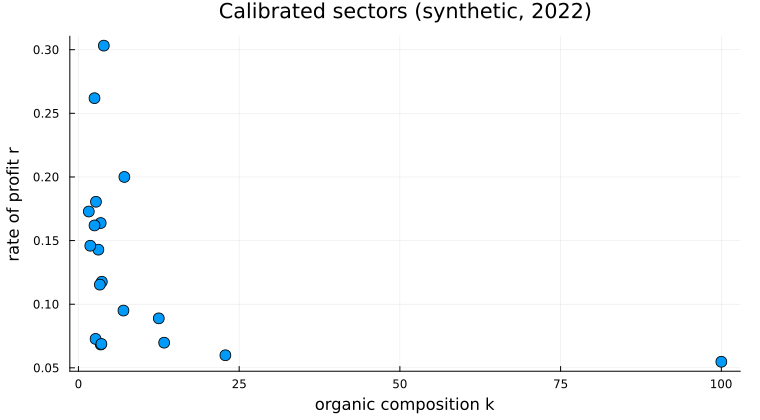

In [4]:
scatter(params.k, params.r, xlabel = "organic composition k", ylabel = "rate of profit r",
        legend = false, title = "Calibrated sectors (synthetic, 2022)", markersize = 6)

## 2. Validating the calibration

`validar_taxas_lucro_calibradas` checks the calibrated profit rates against the wage–profit frontier of the calibrated `A`: whether the average rate is feasible (below `R_max`), how dispersed the rates are, and which sectors are problematic. It prints a report and returns a quality score in percent.

VALIDAÇÃO DE TAXAS DE LUCRO

Ano base: 2022  |  Setores: 19

📊 ESTATÍSTICAS
----------------------------------------------------------------------
  Média:   13.39%
  Mediana: 11.76%
  Mín/Máx: 5.48% / 30.32%
  Desvio-padrão: 6.96pp
  Coef. variação: 0.52

⚙️  Taxa máxima teórica (R_max): 63.04%

🔍 TESTE 1: Viabilidade da Taxa Média
  ✓ Viável — margem: 78.8%

🔍 TESTE 2: Viabilidade Setorial
  ✓ Todos os setores dentro do limite

🔍 TESTE 3: Dispersão (CV = 0.52)
  ⚠️  Moderada
  Lucros anormalmente altos (>2σ):
    • Atividades financeiras e de seguros: 30.3%

🔍 TESTE 4: Consistência
  k médio = 10.59  →  e implícita = 1.55
  ✓ Razoável

🔍 TESTE 5: Posição na Fronteira: 21.2% de R_max
  → Baixa taxa de lucro


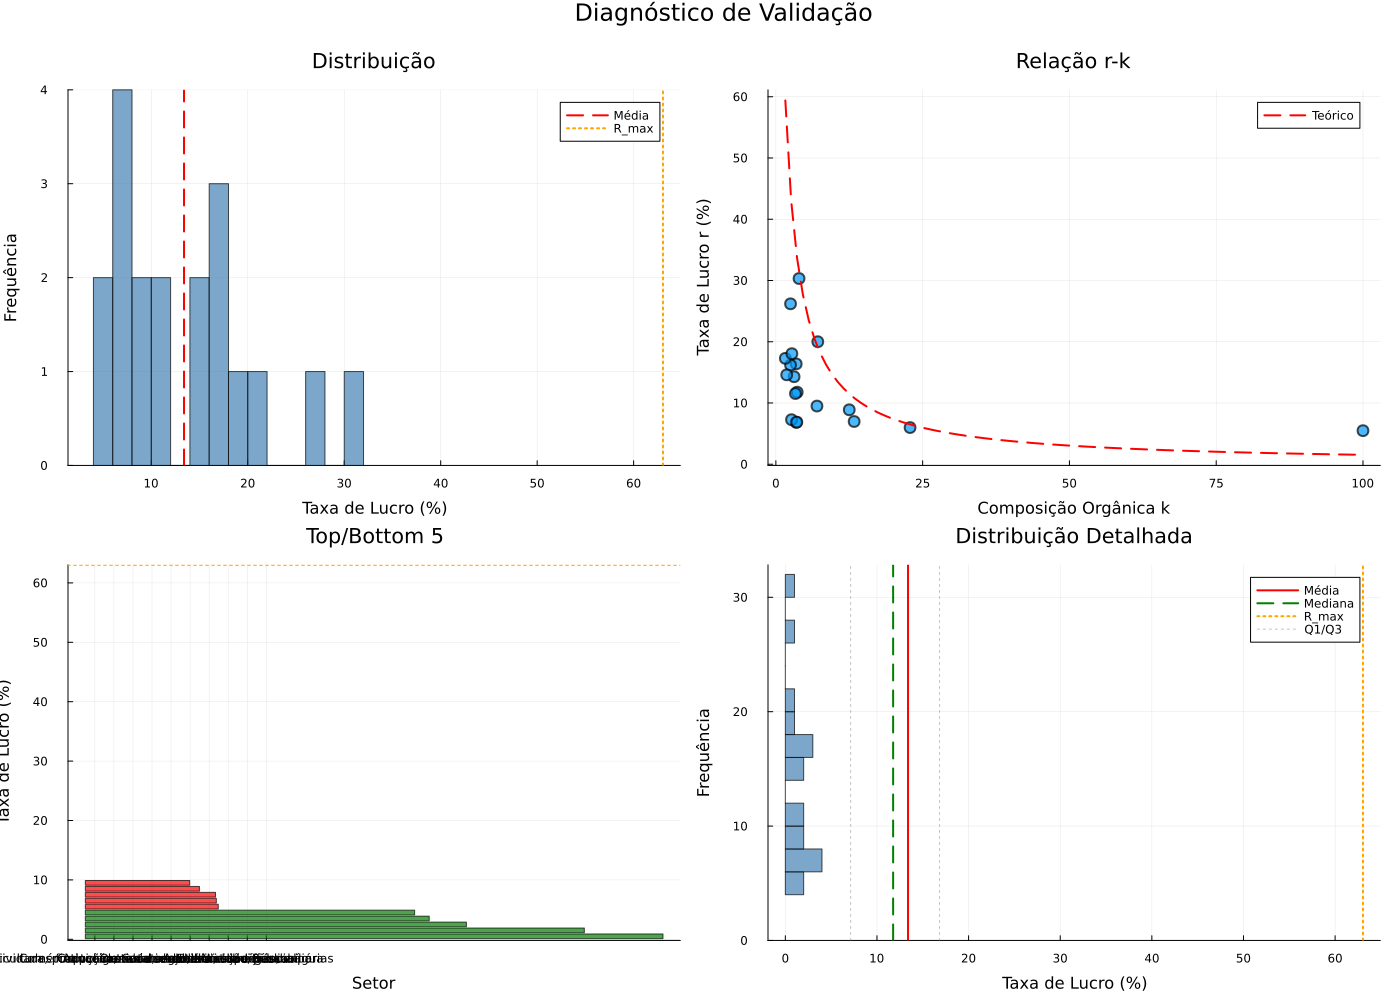


----------------------------------------------------------------------


  PONTUAÇÃO FINAL: 80.0%  ✅ ALTA QUALIDADE



In [5]:
validação = validar_taxas_lucro_calibradas(params);

In [6]:
(R_max = validação.R_max, r_média = validação.r_média, cv = validação.cv,
 pontuação = validação.pontuação, problemáticos = validação.setores_problemáticos)

(R_max = 0.6304304580809768, r_média = 0.13389886808386964, cv = 0.5200731282877861, pontuação = 80.0, problemáticos = Int64[])

## 3. AMECO: any country, three macro-sectors

`calibrar_com_ameco_v2(país; método)` fetches AMECO series and calibrates three macro-sectors. `método = :sintético` generates plausible series offline. The default, `:auto`, tries the official SDMX API first. Country names are in Portuguese (`listar_países_ameco()` lists them).

In [7]:
params_pt, dados_pt = calibrar_com_ameco_v2("Portugal", ano = 2022, método = :sintético)
(setores = params_pt.nomes_setores, e = params_pt.e, k = params_pt.k, r = params_pt.r)


🔬 Gerando dados sintéticos AMECO para PT...


  ✓ 28 anos (1995-2022) | PIB médio 193.1 mil M | desemprego médio 7.0%

CALIBRAÇÃO COM DADOS AMECO — Portugal | Ano: 2022
Fonte: AMECO (sintético)

📊 Dados (2022): PIB 234.0 mil M | Emprego 4.9 M | Stock K 810.1 mil M

📐 Parâmetros marxianos:
  Primário: e=0.59 k=6.66 r=7.71%
  Secundário: e=0.59 k=4.84 r=10.1%
  Terciário: e=0.59 k=7.18 r=7.21%

✅ CALIBRAÇÃO CONCLUÍDA — e médio 0.59 | r médio 8.34%



(setores = ["Primário", "Secundário", "Terciário"], e = [0.5901775836384051, 0.5901775836384051, 0.590177583638405], k = [6.657986788770359, 4.842172210014807, 7.183617324725913], r = [0.07706693677035838, 0.10102023056196581, 0.07211695760201879])

COMPARAÇÃO INTERNACIONAL — AMECO | Ano: 2022
Países: Portugal, Espanha, Itália, Grécia

🌍 Portugal...

🔬 Gerando dados sintéticos AMECO para PT...
  ✓ 28 anos (1995-2022) | PIB médio 193.1 mil M | desemprego médio 7.1%

CALIBRAÇÃO COM DADOS AMECO — Portugal | Ano: 2022
Fonte: AMECO (sintético)

📊 Dados (2022): PIB 234.0 mil M | Emprego 4.9 M | Stock K 810.1 mil M

📐 Parâmetros marxianos:
  Primário: e=0.59 k=6.66 r=7.71%
  Secundário: e=0.59 k=4.84 r=10.1%
  Terciário: e=0.59 k=7.18 r=7.21%

✅ CALIBRAÇÃO CONCLUÍDA — e médio 0.59 | r médio 8.34%


🌍 Espanha...

🔬 Gerando dados sintéticos AMECO para ES...
  ✓ 28 anos (1995-2022) | PIB médio 1155.4 mil M | desemprego médio 12.9%

CALIBRAÇÃO COM DADOS AMECO — Espanha | Ano: 2022
Fonte: AMECO (sintético)

📊 Dados (2022): PIB 1400.0 mil M | Emprego 20.5 M | Stock K 4847.0 mil M

📐 Parâmetros marxianos:
  Primário: e=0.59 k=6.66 r=7.71%
  Secundário: e=0.59 k=4.26 r=11.22%
  Terciário: e=0.59 k=7.48 r=6.96%

✅ CALIBRAÇÃO CONCLUÍDA — e médio 0

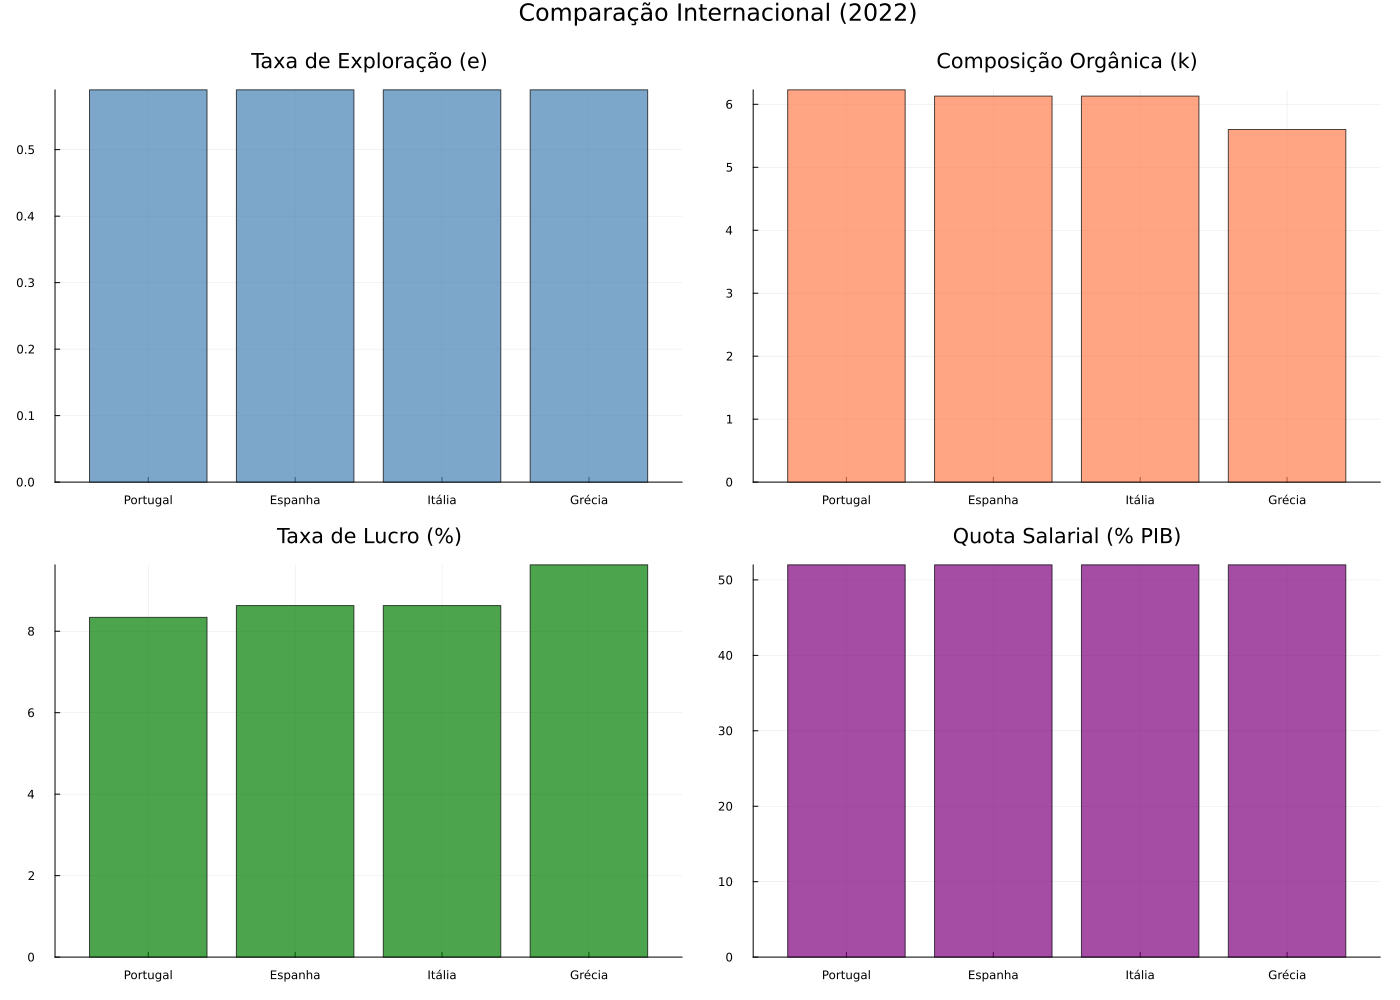

Row,País,PIB,Taxa_Exploração,Comp_Orgânica,Taxa_Lucro,Quota_Salarial
,String,Float64,Float64,Float64,Float64,Float64
1,Portugal,234.0,0.59,6.23,8.34,52.0
2,Espanha,1400.0,0.59,6.13,8.63,52.0
3,Itália,2000.0,0.59,6.13,8.63,52.0
4,Grécia,215.0,0.59,5.6,9.63,52.0


In [8]:
comparação = comparar_países_ameco(["Portugal", "Espanha", "Itália", "Grécia"], ano = 2022)
comparação.tabela

The synthetic AMECO series only exercise the pipeline offline; use `método = :auto` or `:sdmx` for real AMECO data. With the default fixed sectoral weights (`dados_setoriais = :fixo`), value added, wages and depreciation are split in the same proportions, so the rate of surplus value is the same in the three sectors and only the organic composition differs. `dados_setoriais = :eurostat` uses real sectoral data instead.

`analisar_série_temporal_ameco` follows the aggregate rate of surplus value, organic composition, rate of profit and wage share over time.

ANÁLISE DE SÉRIE TEMPORAL — Portugal | 2000-2022

🔬 Gerando dados sintéticos AMECO para PT...
  ✓ 23 anos (2000-2022) | PIB médio 199.5 mil M | desemprego médio 7.0%


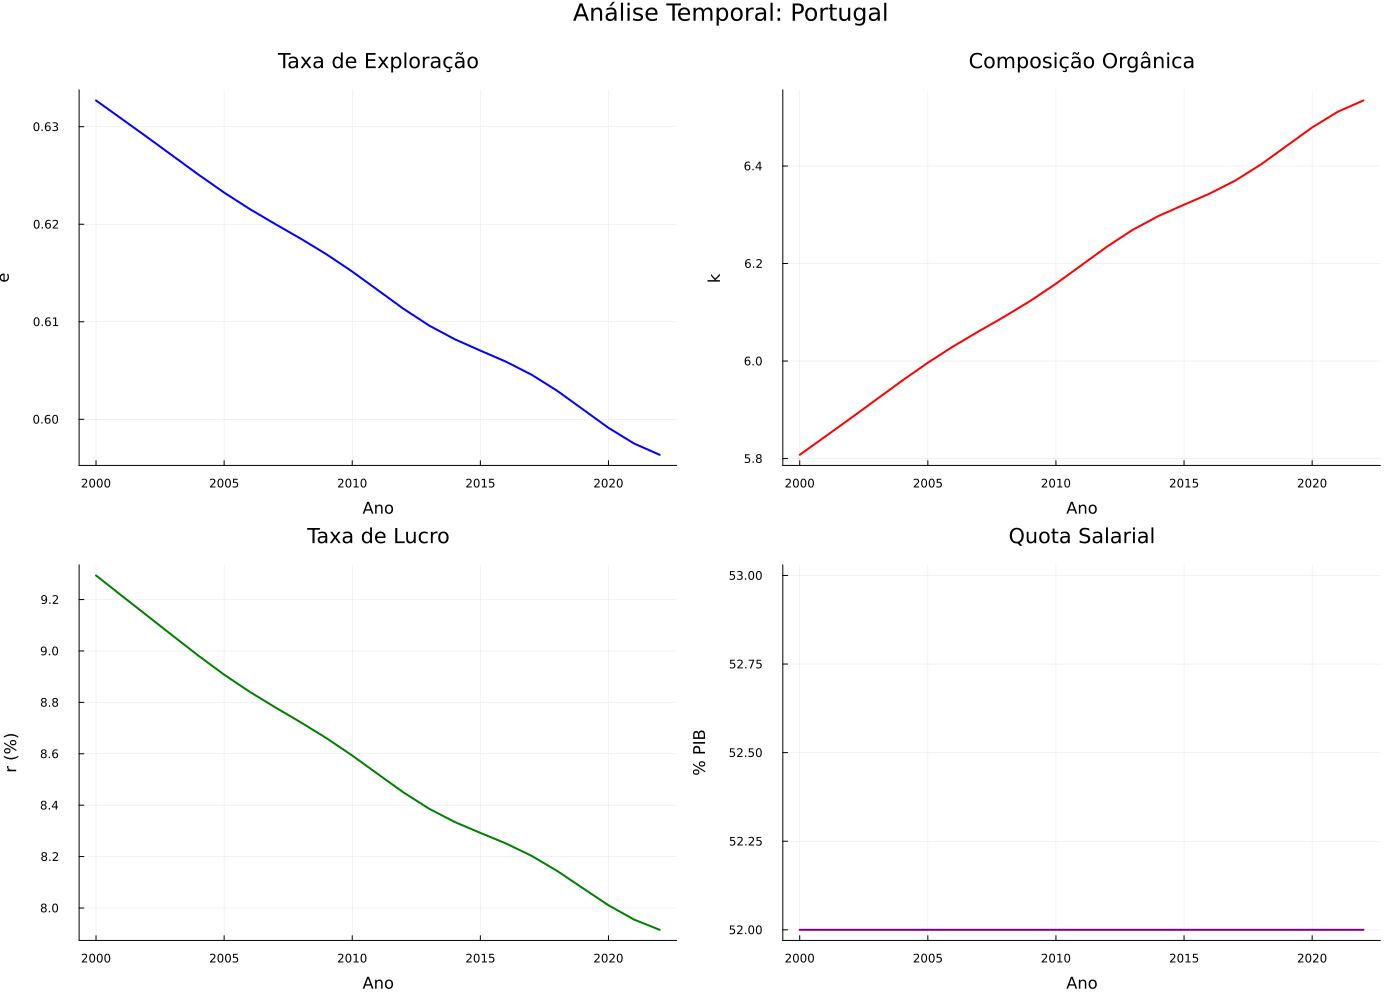


📈 MÉDIAS DO PERÍODO:


  e: 0.61 | k: 6.19 | r: 8.55% | quota salarial: 52.0%



In [9]:
série = analisar_série_temporal_ameco("Portugal", anos = 2000:2022);

## 4. Wage-policy shocks

`simular_choque_salarial(depts, Δw)` runs a baseline and a shocked economy from the same matrix `A`. In the shock, variable capital rises by the factor `1 + Δw` while surplus value is unchanged in the short run, so the rate of surplus value falls by the same factor. It compares the mean sectoral rate of profit of the two runs (`impacto_r_*` are in percentage points). With `plotar = true` it draws the two trajectories and their difference.

SIMULAÇÃO DE CHOQUE SALARIAL — Δw = +10.0%

📈 TAXAS DE LUCRO


  Base:   inicial 44.14%  →  final 50.16%
  Choque: inicial 42.92%  →  final 46.09%
  Impacto: imediato -1.22pp | longo prazo -4.07pp

💰 ACUMULAÇÃO DE CAPITAL
  Base:   +8.1957620708e10%
  Choque: +1.16735289048e10%


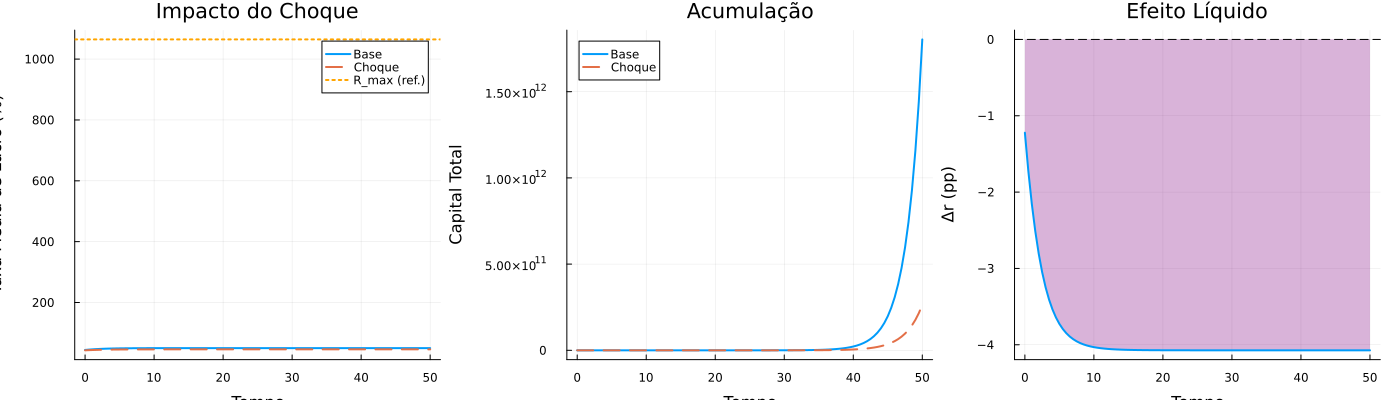

(r_base_final = 0.5016059885214315, r_choque_final = 0.46087677176784686, impacto_r_inicial = -1.222072650183359, impacto_r_final = -4.07292167535846, R_max = 10.645911351606003, viável = true)

In [10]:
Random.seed!(7)
depts = criar_departamentos(6)
choque = simular_choque_salarial(depts, 0.10)

`comparar_choques_salariais` runs several shocks and reports the final mean rate of profit of each, with the baseline (`0.0`) first.


🔬 Comparando 5 cenários de choque...

SIMULAÇÃO DE CHOQUE SALARIAL — Δw = +-20.0%

📈 TAXAS DE LUCRO
  Base:   inicial 44.14%  →  final 50.16%
  Choque: inicial 46.82%  →  final 61.34%
  Impacto: imediato 2.67pp | longo prazo 11.18pp

💰 ACUMULAÇÃO DE CAPITAL
  Base:   +8.1957620708e10%
  Choque: +1.8382216820246e13%

SIMULAÇÃO DE CHOQUE SALARIAL — Δw = +-10.0%

📈 TAXAS DE LUCRO
  Base:   inicial 44.14%  →  final 50.16%
  Choque: inicial 45.44%  →  final 55.13%
  Impacto: imediato 1.3pp | longo prazo 4.97pp

💰 ACUMULAÇÃO DE CAPITAL
  Base:   +8.1957620708e10%
  Choque: +9.009658269657e11%

SIMULAÇÃO DE CHOQUE SALARIAL — Δw = +10.0%

📈 TAXAS DE LUCRO
  Base:   inicial 44.14%  →  final 50.16%
  Choque: inicial 42.92%  →  final 46.09%
  Impacto: imediato -1.22pp | longo prazo -4.07pp

💰 ACUMULAÇÃO DE CAPITAL
  Base:   +8.1957620708e10%
  Choque: +1.16735289048e10%

SIMULAÇÃO DE CHOQUE SALARIAL — Δw = +20.0%

📈 TAXAS DE LUCRO
  Base:   inicial 44.14%  →  final 50.16%
  Choque: inicial 41.77

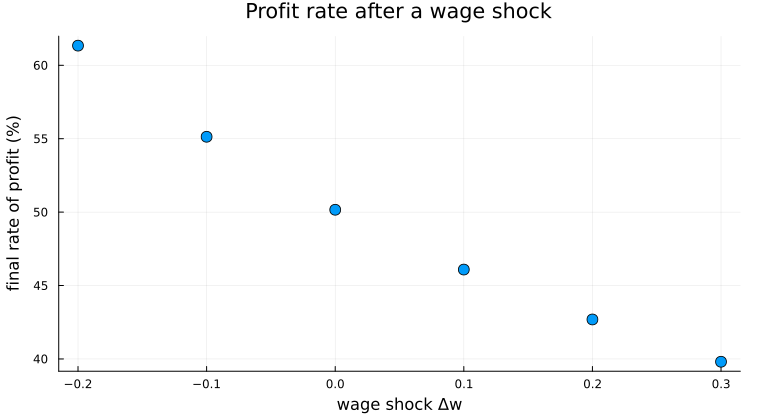

In [11]:
choques = [-0.2, -0.1, 0.1, 0.2, 0.3]
res = comparar_choques_salariais(depts, choques)
plot(getfield.(res, :choque), 100 .* getfield.(res, :r_final), seriestype = :scatter,
     markersize = 6, legend = false, xlabel = "wage shock Δw",
     ylabel = "final rate of profit (%)", title = "Profit rate after a wage shock")

## 5. Real data (opt-in, needs network)

These calls are not run here. They replace the synthetic structure with Eurostat sectoral accounts and the real input–output matrix (`NAIO_10_CP1700`, domestic flows):

```julia
params_real = calibrar_modelo_portugal(ano = 2022, fonte_dados = :eurostat)
params_real, dados = calibrar_com_ameco_v2("Portugal", ano = 2022, dados_setoriais = :eurostat)
verificar_sdmx_ameco()          # check access to the AMECO SDMX API
verificar_eurostat_setorial()   # check access to the Eurostat API
```

See `docs/LIMITACOES.en.md` for the status of each data path.